In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/processed_orders.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (2017, 29)


,order_id,order_datetime,customer_name,phone,address,city,state,pincode,order_value,items,...,address_quality_score,name_valid,pincode_valid,high_value_order,value_per_item,order_hour,order_day,order_weekday,is_weekend,is_rto
0,KT100193,2026-06-18 15:34:00,Lakshmi Shaikh,6007018646,"Station chowk se left, Hanuman Mandir ke saamne",Chennai,Tamil Nadu,600084.0,349,Satin Pillowcase,...,80,1,1,0,349.0,15,18,3,0,0
1,KT101714,2026-07-26 09:36:00,Tanvi Das,9895118261,"Link chowk se left, SBI Bank ke saamne",Indore,Madhya Pradesh,452026.0,898,Rice Water Shampoo Bar|Satin Bonnet,...,80,1,1,0,449.0,9,26,6,1,0
2,KT100452,2026-05-29 22:37:00,Swati Das,9583831354,"399/13, Station Nagar, Opp. Railway Crossing",Chennai,Tamil Nadu,600092.0,449,Satin Pillowcase,...,100,1,1,0,449.0,22,29,4,0,0
3,KT101753,2026-06-29 12:46:00,Meera Pillai,9109605378,"784/17, MG Nagar, Opp. Hanuman Mandir",Lucknow,Uttar Pradesh,226036.0,699,Satin Bonnet,...,100,1,1,0,699.0,12,29,0,0,1
4,KT100195,2026-05-13 14:15:00,Sneha Reddy,6763180097,"ph krke aana, Govt School ke paas",Hyderabad,Telangana,500058.0,499,Claw Clip Set,...,50,1,1,0,499.0,14,13,2,0,0


In [3]:
print(df['is_rto'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

is_rto
0    1444
1     573
Name: count, dtype: int64

Missing values:
order_id                       0
order_datetime                 0
customer_name                  0
phone                          0
address                        0
city                           0
state                          0
pincode                       12
order_value                    0
items                          0
num_items                      0
customer_prior_orders          0
customer_prior_rto             0
utm_source                     0
courier                        0
payment_method                 0
final_status                   0
customer_rto_rate              0
customer_successful_orders     0
address_quality_score          0
name_valid                     0
pincode_valid                  0
high_value_order               0
value_per_item                 0
order_hour                     0
order_day                      0
order_weekday                  0
is_weekend                     0
is_rto

In [4]:
before = len(df)

df = df.drop_duplicates(
    subset=['order_id'],
    keep='first'
).copy()

print("Records removed:", before - len(df))
print("Remaining records:", len(df))

Records removed: 30
Remaining records: 1987


In [5]:
numeric_features = [
    'order_value',
    'num_items',
    'customer_prior_orders',
    'customer_prior_rto',
    'customer_rto_rate',
    'customer_successful_orders',
    'address_quality_score',
    'name_valid',
    'pincode_valid',
    'high_value_order',
    'value_per_item',
    'order_hour',
    'order_weekday',
    'is_weekend'
]

In [6]:
categorical_features = [
    'city',
    'state',
    'courier',
    'utm_source'
]

In [7]:
feature_columns = (
    numeric_features + categorical_features
)

X = df[feature_columns].copy()

y = df['is_rto'].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1987, 18)
y shape: (1987,)


In [8]:
df['order_datetime'] = pd.to_datetime(
    df['order_datetime'],
    errors='coerce'
)

df = df.dropna(subset=['order_datetime'])

df = df.sort_values('order_datetime').reset_index(drop=True)

split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()

test_df = df.iloc[split_index:].copy()

X_train = train_df[feature_columns]
y_train = train_df['is_rto']

X_test = test_df[feature_columns]
y_test = test_df['is_rto']

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining RTO rate:")
print(y_train.mean())

print("\nTesting RTO rate:")
print(y_test.mean())

Training records: 1589
Testing records: 398

Training RTO rate:
0.29011957205789807

Testing RTO rate:
0.2613065326633166


In [9]:
numeric_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(strategy='median')
        ),
        (
            'scaler',
            StandardScaler()
        )
    ]
)

In [10]:
categorical_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(strategy='most_frequent')
        ),
        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore'
            )
        )
    ]
)

In [11]:
categorical_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(strategy='most_frequent')
        ),
        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore'
            )
        )
    ]
)

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            numeric_transformer,
            numeric_features
        ),
        (
            'cat',
            categorical_transformer,
            categorical_features
        )
    ]
)

In [14]:
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        (
            'classifier',
            LogisticRegression(
                max_iter=2000,
                class_weight='balanced',
                random_state=42
            )
        )
    ]
)

In [15]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [16]:
lr_predictions = logistic_model.predict(X_test)

lr_probabilities = (
    logistic_model.predict_proba(X_test)[:, 1]
)

Train Model 2: Random Forest

In [17]:
random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        (
            'classifier',
            RandomForestClassifier(
                n_estimators=300,
                max_depth=12,
                min_samples_split=10,
                min_samples_leaf=4,
                class_weight='balanced',
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [18]:
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [19]:
rf_predictions = (
    random_forest_model.predict(X_test)
)

rf_probabilities = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

In [20]:
def evaluate_model(name, y_true, predictions, probabilities):

    return {
        'Model': name,

        'Accuracy': accuracy_score(
            y_true,
            predictions
        ),

        'Precision': precision_score(
            y_true,
            predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_true,
            predictions,
            zero_division=0
        ),

        'F1 Score': f1_score(
            y_true,
            predictions,
            zero_division=0
        ),

        'ROC AUC': roc_auc_score(
            y_true,
            probabilities
        ),

        'PR AUC': average_precision_score(
            y_true,
            probabilities
        )
    }

In [21]:
results = []

results.append(
    evaluate_model(
        'Logistic Regression',
        y_test,
        lr_predictions,
        lr_probabilities
    )
)

results.append(
    evaluate_model(
        'Random Forest',
        y_test,
        rf_predictions,
        rf_probabilities
    )
)

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC AUC  \
0  Logistic Regression  0.690955   0.437086  0.634615  0.517647  0.725013   
1        Random Forest  0.728643   0.485294  0.634615  0.550000  0.728578   

     PR AUC  
0  0.496479  
1  0.533389  


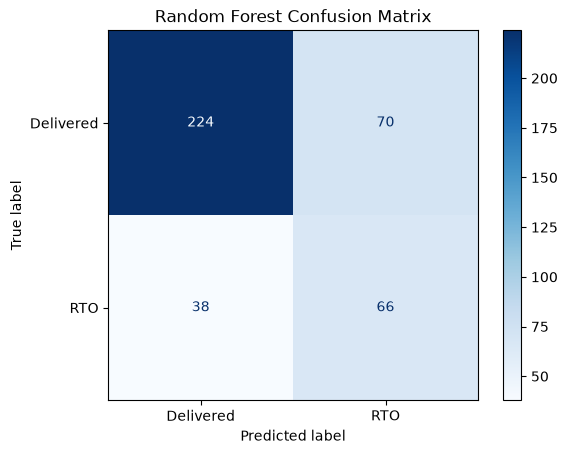

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=[
        'Delivered',
        'RTO'
    ],
    cmap='Blues'
)

plt.title('Random Forest Confusion Matrix')

plt.show()

In [23]:
os.makedirs('../models', exist_ok=True)

In [24]:
joblib.dump(
    logistic_model,
    '../models/logistic_regression.pkl'
)

joblib.dump(
    random_forest_model,
    '../models/random_forest.pkl'
)

print("Models saved successfully!")

Models saved successfully!
